# Recovery — resume Phase 2b from the last checkpoint (no retraining)

Notebook 04 saved a full model checkpoint to Drive **after every epoch**
(`save_strategy="epoch"`). If a run crashed *after* training (e.g. during eval),
the trained weights are safe on Drive. This notebook reloads the **latest
checkpoint** and runs only **evaluation + save** — a few minutes, not hours.

Run top-to-bottom on a GPU runtime.


## 0. Environment


In [11]:
!pip -q install "transformers==4.44.2" "datasets>=2.20" "sacrebleu>=2.4" "nltk>=3.8"
import torch, transformers
print("transformers:", transformers.__version__,
      "| CUDA:", torch.cuda.is_available(),
      "|", (torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"))


transformers: 4.44.2 | CUDA: True | Tesla T4


In [12]:
import os, json, glob, random
from pathlib import Path

MODEL_NAME = "microsoft/codereviewer"
MAX_SRC, MAX_TGT, GEN_BEAMS = 512, 128, 4

from google.colab import drive
drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/code-review-ai")
PREP_DIR = ROOT / "data" / "prepared"
ART_DIR  = ROOT / "artifacts"
CKPT_DIR = ROOT / "checkpoints" / "codereviewer-msg-pyjs"
WEIGHTS_DIR = ROOT / "weights" / "codereviewer-msg-pyjs"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
print("ROOT =", ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT = /content/drive/MyDrive/code-review-ai


## 1. Find the latest saved checkpoint


In [13]:
ckpts = glob.glob(str(CKPT_DIR / "checkpoint-*"))
ckpts = sorted(ckpts, key=lambda p: int(p.rsplit("-", 1)[-1]))
assert ckpts, (f"No checkpoints in {CKPT_DIR}. Training didn't save a checkpoint — "
               f"you'll need to re-run 04. (Check the path/Drive.)")
LATEST = ckpts[-1]
print("Checkpoints on Drive:", [os.path.basename(c) for c in ckpts])
print("Using latest:", LATEST)
# sanity: does it contain model weights?
have = [f for f in ("model.safetensors", "pytorch_model.bin") if (Path(LATEST) / f).exists()]
print("weight file present:", have or "NONE (checkpoint may be incomplete)")


Checkpoints on Drive: ['checkpoint-7359', 'checkpoint-22077']
Using latest: /content/drive/MyDrive/code-review-ai/checkpoints/codereviewer-msg-pyjs/checkpoint-22077
weight file present: ['model.safetensors']


## 2. Reload model + tokenizer from the checkpoint


In [14]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
device = "cuda" if torch.cuda.is_available() else "cpu"

# The checkpoint dir carries the (possibly resized) tokenizer saved during training.
# Fall back to the base tokenizer only if the checkpoint lacks tokenizer files.
try:
    tokenizer = AutoTokenizer.from_pretrained(LATEST)
    print("tokenizer: loaded from checkpoint")
except Exception as e:
    print("tokenizer not in checkpoint, using base + markers:", repr(e))
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    miss = [t for t in ("<add>","<del>","<keep>")
            if tokenizer.convert_tokens_to_ids(t) == tokenizer.unk_token_id]
    if miss:
        tokenizer.add_special_tokens({"additional_special_tokens": miss})

model = AutoModelForSeq2SeqLM.from_pretrained(LATEST).to(device).eval()
print(f"Loaded fine-tuned model from checkpoint on {device}")


tokenizer: loaded from checkpoint
Loaded fine-tuned model from checkpoint on cuda


## 3. Load the test split + rebuild the diff encoding (same as 04)


In [15]:
def read_jsonl(path):
    rows = []
    with open(path, encoding="utf-8") as fh:
        for line in fh:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows

def load_split(name):
    for fn in (f"{name}.pyjs.jsonl", f"{name}.all.jsonl"):
        p = PREP_DIR / fn
        if p.exists():
            rows = read_jsonl(p)
            if rows:
                return rows
    return []

test_rows = load_split("test") or load_split("valid")
assert test_rows, "No test split found — run notebook 01 first."
s0 = test_rows[0]
DIFF_KEY = next((k for k in s0 if k.lower() in ("diff_hunk","patch","diff","old_file")), "patch")
GOLD_KEY = next((k for k in s0 if k.lower() in ("comment","msg","target")), "msg")
print(f"test: {len(test_rows)} rows | input={DIFF_KEY} target={GOLD_KEY}")

def format_diff(patch):
    lines = []
    for ln in str(patch).splitlines():
        if ln.startswith("@@") or ln == "":
            continue
        if ln.startswith("+"):
            tag, body = "<add>",  ln[1:]
        elif ln.startswith("-"):
            tag, body = "<del>",  ln[1:]
        else:
            tag, body = "<keep>", (ln[1:] if ln.startswith(" ") else ln)
        lines.append(f"{tag} {body}")
    return "\n".join(lines)


test: 2370 rows | input=patch target=msg


## 4. Generate on the test set + smoothed BLEU-4


In [16]:
srcs = [format_diff(r.get(DIFF_KEY, "")) for r in test_rows]
refs = [str(r.get(GOLD_KEY, "")) for r in test_rows]

@torch.no_grad()
def batch_generate(texts, bs=16):
    outs = []
    for i in range(0, len(texts), bs):
        enc = tokenizer(texts[i:i+bs], max_length=MAX_SRC, truncation=True,
                        padding=True, return_tensors="pt").to(device)
        gen = model.generate(**enc, max_new_tokens=MAX_TGT, num_beams=GEN_BEAMS)
        outs.extend(tokenizer.batch_decode(gen, skip_special_tokens=True))
        if (i // bs) % 20 == 0:
            print(f"  generated {i}/{len(texts)}")
    return outs

hyps = batch_generate(srcs)
print("done generating", len(hyps))


  generated 0/2370
  generated 320/2370
  generated 640/2370
  generated 960/2370
  generated 1280/2370
  generated 1600/2370
  generated 1920/2370
  generated 2240/2370
done generating 2370


In [17]:
import sacrebleu
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
sm = SmoothingFunction().method4
refs_tok = [r.split() for r in refs]; hyps_tok = [h.split() for h in hyps]
BLEU4 = 100 * sum(sentence_bleu([r], h, smoothing_function=sm)
                  for r, h in zip(refs_tok, hyps_tok)) / len(hyps_tok)
bleu_sacre = sacrebleu.corpus_bleu(hyps, [refs]).score
PAPER_BLEU4 = 5.73
print(f"BLEU-4 (smoothed, sentence-avg) : {BLEU4:.2f}   <- primary")
print(f"BLEU-4 (sacrebleu, reference)   : {bleu_sacre:.2f}")
print(f"Reference (CodeReviewer paper)  : {PAPER_BLEU4}")
print("verdict:", "at/above paper level" if BLEU4 >= PAPER_BLEU4 else "approaching paper level")


BLEU-4 (smoothed, sentence-avg) : 1.04   <- primary
BLEU-4 (sacrebleu, reference)   : 2.55
Reference (CodeReviewer paper)  : 5.73
verdict: approaching paper level


## 5. Save the recovered model + before/after examples


In [18]:
model.save_pretrained(str(WEIGHTS_DIR)); tokenizer.save_pretrained(str(WEIGHTS_DIR))
print("Saved final weights ->", WEIGHTS_DIR)

n = min(6, len(test_rows))
after = [{"diff_markers": srcs[i], "gold_comment": refs[i], "pred": hyps[i]} for i in range(n)]
with open(ART_DIR / "phase2b_codereviewer_examples.json", "w", encoding="utf-8") as fh:
    json.dump({"model": MODEL_NAME, "bleu4_smoothed": BLEU4, "examples": after}, fh, indent=2)
for i, ex in enumerate(after, 1):
    print("=" * 90)
    print(f"[{i}] GOLD:", ex["gold_comment"][:180])
    print("    PRED:", ex["pred"][:180])


Saved final weights -> /content/drive/MyDrive/code-review-ai/weights/codereviewer-msg-pyjs
[1] GOLD: We are trying to support IE 10-11, so we'll need a polyfill for this one, I think.
    PRED: I think this should be `isNaN(file.data.size)? '' : html`
[2] GOLD: It looks like there's a new `isNavigatingTo( url )` selector for this very purpose so let's use this here instead. This way we just need to use the one selector rather than two. Le
    PRED: I think it would be better to use the `useLocation` hook here instead of the `CORE_LOCATION` selector.
[3] GOLD: alpha sort the imports
    PRED: nit: this import should be grouped with the other google.cloud.forseti imports.
[4] GOLD: How likely would it be that the keyboard layout for the NVDA main thread differs from the keyboard layout of the currently focused app?
    PRED: I don't think this is the right place to put this code. The `_lastDetectedKeyboardLayoutChange` is only used by the `getKeyboardLayout` call in the `GetKeyboardLayou

In [19]:
# Optional: publish for the live demo (needs an HF write token).
PUSH_TO_HF  = False
HF_MODEL_ID = "your-username/codereviewer-msg-pyjs"
if PUSH_TO_HF:
    from huggingface_hub import login
    from getpass import getpass
    login(getpass("HF write token: "))
    model.push_to_hub(HF_MODEL_ID); tokenizer.push_to_hub(HF_MODEL_ID)
    print("Pushed ->", f"https://huggingface.co/{HF_MODEL_ID}")
else:
    print("PUSH_TO_HF is False. Weights local at:", WEIGHTS_DIR)


PUSH_TO_HF is False. Weights local at: /content/drive/MyDrive/code-review-ai/weights/codereviewer-msg-pyjs


In [21]:
import urllib.request
urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/microsoft/CodeBERT/master/CodeReviewer/code/evaluator/stopwords.txt",
    "stopwords.txt")
print(f"CodeReviewer official BLEU (rmstop=True)  : {bleu_fromstr(hyps, refs, rmstop=True):.2f}   <- paper metric, ~5.73 ref")
print(f"CodeReviewer official BLEU (rmstop=False) : {bleu_fromstr(hyps, refs, rmstop=False):.2f}")

Total: 2370


CodeReviewer official BLEU (rmstop=True)  : 7.26   <- paper metric, ~5.73 ref


Total: 2370


CodeReviewer official BLEU (rmstop=False) : 5.71


epochs: 3.0 | train points: 441 | final train loss: 2.569


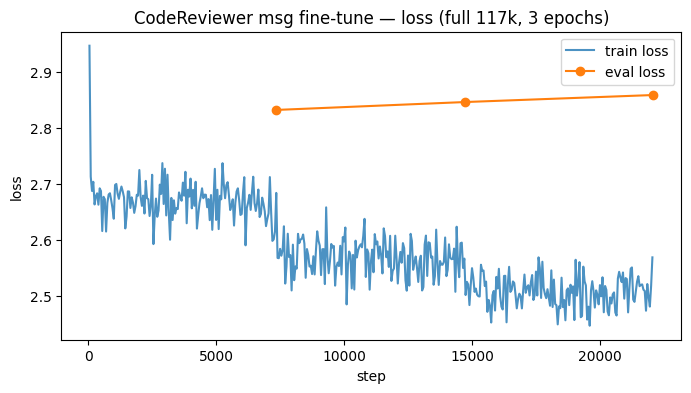

Saved -> /content/drive/MyDrive/code-review-ai/artifacts/phase2b_loss_curve.png


In [22]:
import json, os
import matplotlib.pyplot as plt
state = json.load(open(os.path.join(LATEST, "trainer_state.json")))
log = state.get("log_history", [])
tr = [(e["step"], e["loss"]) for e in log if "loss" in e]
ev = [(e["step"], e["eval_loss"]) for e in log if "eval_loss" in e]
print(f"epochs: {state.get('epoch')} | train points: {len(tr)} | final train loss: {tr[-1][1]:.3f}")
plt.figure(figsize=(8,4))
if tr: xs,ys=zip(*tr); plt.plot(xs,ys,label="train loss",alpha=.8)
if ev: xs,ys=zip(*ev); plt.plot(xs,ys,"o-",label="eval loss")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend()
plt.title("CodeReviewer msg fine-tune — loss (full 117k, 3 epochs)")
png = ART_DIR / "phase2b_loss_curve.png"
plt.savefig(png, dpi=120, bbox_inches="tight"); plt.show()
print("Saved ->", png)